# Predicting Explanation Error Without Causal Ground Truth
## A Held-Out-SCM Study of SHAP and LIME

**Team DataSphere (Section G)** — Bhuvi S. Katti, Mythri S, Poojitha L. B. R., Diran Somanna
Advanced Data Analytics (Sem 5), PES University · code: https://github.com/stacktrace-bhuvi/datasphere

SHAP and LIME describe *the model*; people read them as statements about *the world* ("this feature drives the outcome").
With real data nobody can tell when that reading is wrong, because the causal truth is unknown.
This notebook walks through our five-stage pipeline on live examples, then reproduces the headline results of the
report from the full 300-SCM run.

| Stage | What | Code |
|---|---|---|
| 1 | Synthetic causal worlds (SCMs) from 5 graph families | `src/scm/graph.py`, `mechanisms.py`, `scm.py` |
| 2 | Causal ground truth: total effect $\tau_j$ under $do(X_j)$, exact SHAP of the true function $f^*$ | `scm.py::true_effects`, `oracle.py`, `ground_truth.py` |
| 3 | Models (XGBoost, MLP) + explainers (exact SHAP, TreeSHAP, KernelSHAP, LIME, permutation) | `src/models`, `src/explainers` |
| 4 | Error decomposition (needs truth) and observables (no truth) | `src/metrics`, `src/observables` |
| 5 | Diagnostic meta-models vs baselines; grouped CV, leave-one-graph-family-out, paired tests | `src/diagnostic` |

### 0. Setup
Run from the repository root (the cell clones the repo if needed, e.g. on Colab).

In [1]:
import os, sys, json, pathlib, subprocess, warnings
if not pathlib.Path("src/scm/scm.py").exists():
    if pathlib.Path("../src/scm/scm.py").exists():
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "https://github.com/stacktrace-bhuvi/datasphere.git"], check=True)
        os.chdir("datasphere")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
ROOT = pathlib.Path.cwd(); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
from IPython.display import Image, display
print("repo root:", ROOT)

repo root: datasphere


## Stage 1 — A causal world with known structure

An SCM is a DAG over features $X_1..X_d$ and a sink $Y$, plus one structural equation per node
($X_v = f_v(\text{parents}) + \varepsilon_v$). We draw the graph from one of five families and the mechanisms
at random (linear, tanh, sin, quadratic, ReLU, pairwise interaction). Below: a chain-mediation world.

family: chain_mediation | d = 6 | non-linear nodes: 5 | confounding: True | mediation share: 0.8333333333333334
  X6 <- ['(root)']  linear  nl=[]
  X5 <- ['X6']  nonlinear_additive  nl=['quadratic']
  X1 <- ['X5']  nonlinear_additive  nl=['tanh']
  X2 <- ['X1']  nonlinear_additive  nl=['tanh']
  X3 <- ['X2']  nonlinear_additive  nl=['quadratic']
  X4 <- ['X3']  nonlinear_additive  nl=['sin']
   Y <- ['X4', 'X5']  linear  nl=['linear', 'linear']


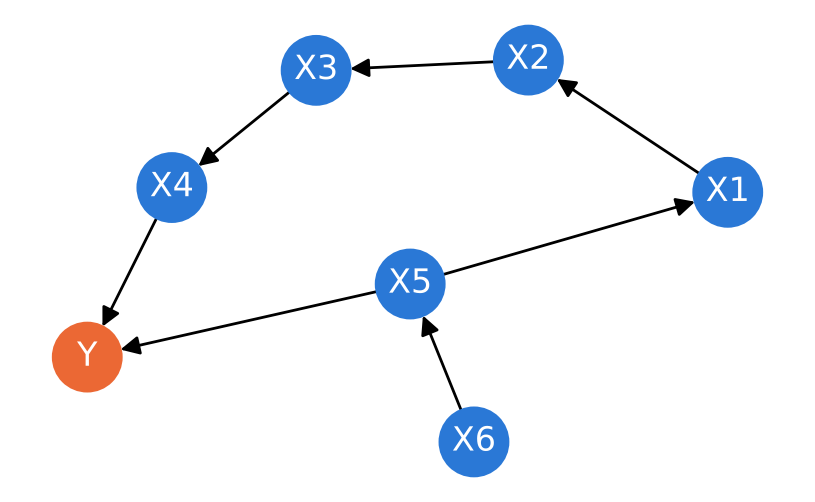

,X1,X2,X3,X4,X5,X6,Y
mean,0.011,0.669,-0.111,0.203,-0.220,-0.100,-0.417
std,0.722,0.721,0.904,0.723,0.832,0.835,0.460


In [2]:
from src.scm.scm import SCM
scm = SCM.build("chain_mediation", d=6, seed=3, nonlinearity_prob=0.5, interaction_prob=0.2, outcome_noise_scale=0.4)
print("family:", scm.metadata["family"], "| d =", scm.d, "| non-linear nodes:", scm.metadata["n_nonlinear"],
      "| confounding:", scm.metadata["has_confounding"], "| mediation share:", scm.metadata["mediation_share"])
for node in scm.topological_order:
    m = scm.mechanisms[node]
    print(f"  {node:>2} <- {m.parents or ['(root)']}  {m.mechanism_type}  nl={m.nonlinearities}")
fig, ax = plt.subplots(figsize=(5, 3))
pos = nx.nx_agraph.graphviz_layout(scm.graph, prog="dot") if hasattr(nx, "nx_agraph") and False else nx.spring_layout(scm.graph, seed=2)
nx.draw_networkx(scm.graph, pos, ax=ax, node_color=["#eb6834" if n == "Y" else "#2a78d6" for n in scm.graph.nodes],
                 font_color="white", node_size=600, arrowsize=14)
ax.set_axis_off(); plt.show()
df = scm.sample(2000, seed=3)
df.describe().loc[["mean", "std"]]

## Stage 2 — Causal ground truth

Two quantities, both computable only because we built the world:

* **Total interventional effect** $\tau_j = \mathbb{E}_x\big|\mathbb{E}[Y\mid do(X_j = x+\sigma_j)] - \mathbb{E}[Y\mid do(X_j = x-\sigma_j)]\big| / 2$,
  by nested Monte Carlo with common random numbers (noise averaged *before* the absolute value).
* **Exact interventional SHAP of the true function** $f^*(x) = \mathbb{E}[Y \mid \text{pa}(Y)]$ on 100 fixed explain rows
  with 50 background rows — the attribution a *perfect* model and a *perfect* explainer would give.

In a chain every upstream feature truly moves $Y$, but $f^*$ only reads the parents of $Y$ — so exact SHAP gives
the mediated features **zero**. That is the *estimand gap*: SHAP is faithful to the model, not to the world.

In [3]:
from src.scm.oracle import mean_abs_shap
tau = scm.true_effects(n_ref=50, n_noise_per_ref=5000, seed=3)
X = df[scm.features].to_numpy()
phi_star = mean_abs_shap(scm.f_star, X[:100], X[100:150])
shares = lambda v: np.abs(v) / np.abs(v).sum()
pd.DataFrame({"tau (true effect)": tau, "exact SHAP of f*": phi_star,
              "share tau": shares(tau), "share SHAP": shares(phi_star)}, index=scm.features).round(3)

,tau (true effect),exact SHAP of f*,share tau,share SHAP
X1,0.052,0.000,0.049,0.000
X2,0.103,0.000,0.096,0.000
X3,0.189,0.000,0.177,0.000
X4,0.305,0.254,0.286,0.545
X5,0.235,0.212,0.220,0.455
X6,0.184,0.000,0.173,0.000


## Stage 3 — Fit models, run explainers

Both models are trained on the same 60/20/20 split; all explainers see the same 100 explain / 50 background rows
as the oracle. `exact` is brute-force interventional SHAP of the **fitted** model (all $2^d$ coalitions) — the $\Phi(f)$ term.

In [4]:
from src.models import train_model, split_xy
from src.explainers import explain, supports
n = len(df); split = np.array(["train"] * int(.6 * n) + ["val"] * int(.2 * n) + ["test"] * (n - int(.6 * n) - int(.2 * n)))
np.random.default_rng(0).shuffle(split); df["row_split"] = split
parts = split_xy(df, scm.features)
X_exp = df[df.row_split == "test"][scm.features].to_numpy()[:100]
X_bg = df[df.row_split == "train"][scm.features].to_numpy()[:50]
rows = {}
for name in ("xgboost", "mlp"):
    model = train_model(name, df, seed=0)
    print(f"{name}: test R^2 = {model.metrics['test_r2']:.3f}")
    for ex in ("exact", "treeshap", "kernelshap", "lime", "permutation"):
        if supports(model, ex):
            a = explain(model, ex, X_exp, X_bg, seed=0, X_train=parts["train"][0], X_test=parts["test"][0], y_test=parts["test"][1])
            rows[(name, ex)] = shares(a.mean_abs)
tab = pd.DataFrame(rows, index=scm.features).T
tab.insert(0, "", "")
pd.concat([pd.DataFrame([shares(tau), shares(phi_star)], index=[("truth", "tau"), ("truth", "exact SHAP f*")], columns=scm.features), tab.drop(columns="")]).round(3)

xgboost: test R^2 = 0.667


mlp: test R^2 = 0.680


,X1,X2,X3,X4,X5,X6
"(truth, tau)",0.049,0.096,0.177,0.286,0.220,0.173
"(truth, exact SHAP f*)",0.000,0.000,0.000,0.545,0.455,0.000
"(xgboost, exact)",0.016,0.024,0.020,0.473,0.459,0.008
"(xgboost, treeshap)",0.016,0.024,0.020,0.473,0.459,0.008
"(xgboost, kernelshap)",0.021,0.024,0.023,0.466,0.453,0.013
"(xgboost, lime)",0.012,0.022,0.014,0.476,0.472,0.005
"(xgboost, permutation)",0.000,0.001,0.004,0.513,0.479,0.003
"(mlp, exact)",0.030,0.082,0.045,0.410,0.395,0.039
"(mlp, kernelshap)",0.032,0.083,0.047,0.409,0.390,0.040
"(mlp, lime)",0.023,0.082,0.035,0.420,0.415,0.024


## Stage 4a — Where does the error come from?

$\tau \to \Phi(f^*) \to \Phi(f) \to \hat E(f)$: the three vector differences telescope exactly.
We report each component as an $L_2$ distance between **importance shares** (scale-free), as `1 - Kendall tau-b`
(rank space) and as normalized $L_2$ (raw space, as in SCHEMAS.md).

In [5]:
from src.metrics import decompose_error
model = train_model("xgboost", df, seed=0)
exact = explain(model, "exact", X_exp, X_bg).mean_abs
for ex in ("kernelshap", "lime", "permutation"):
    emp = explain(model, ex, X_exp, X_bg, seed=0, X_train=parts["train"][0], X_test=parts["test"][0], y_test=parts["test"][1]).mean_abs
    r = decompose_error(tau, phi_star, exact, emp)
    print(f"{ex:12s} total(rank)={r['total_error_rank']:.2f}  total(share)={r['total_error_share_l2']:.3f}  "
          f"| gap={r['estimand_gap_share']:.3f}  misfit={r['model_misfit_share']:.3f}  explainer={r['explainer_error_share']:.3f}")

kernelshap   total(rank)=0.40  total(share)=0.376  | gap=0.442  misfit=0.080  explainer=0.012


lime         total(rank)=0.40  total(share)=0.401  | gap=0.442  misfit=0.080  explainer=0.016
permutation  total(rank)=0.00  total(share)=0.435  | gap=0.442  misfit=0.080  explainer=0.055


## Stage 4b — Observables: what you *can* measure without the truth

Everything below is computed from the training data, the fitted model, held-out labels and the attributions themselves.

In [6]:
from src.observables import data_observables, model_observables, concentration_observables, explainer_disagreement, perturb_inputs, perturbation_observables
obs = data_observables(parts["train"][0], parts["train"][1])
obs.update(model_observables(model, parts))
attrs = {ex: explain(model, ex, X_exp, X_bg, seed=0, X_train=parts["train"][0], X_test=parts["test"][0], y_test=parts["test"][1])
         for ex in ("kernelshap", "lime", "permutation")}
obs.update(concentration_observables(attrs["kernelshap"].values))
obs.update(explainer_disagreement("kernelshap", {k: a.mean_abs for k, a in attrs.items()}))
X_p = perturb_inputs(X_exp, parts["train"][0], 0.05, seed=1)
obs.update(perturbation_observables(attrs["kernelshap"].values, explain(model, "kernelshap", X_p, X_bg, seed=0).values, X_exp, X_p))
pd.Series(obs, name="KernelSHAP on XGBoost").to_frame().round(3).T

,max_abs_corr,mean_abs_corr,frac_corr_gt_0_3,max_vif,mean_vif,mutual_info_max,mutual_info_mean,max_abs_corr_xy,mean_abs_corr_xy,mi_xy_max,mi_xy_mean,n_train,d,test_mse,test_r2,val_mse,train_r2,overfit_gap,pred_var_ratio,resid_kurtosis,attribution_gini,top1_share,effective_features,sign_consistency,local_dispersion,disagreement_rank_mean,disagreement_l2_mean,disagreement_topk_mean,disagreement_rank_vs_lime,disagreement_l2_vs_lime,perturb_stability_rank,perturb_rel_change,sensitivity,global_share_shift
KernelSHAP on XGBoost,0.581,0.246,0.267,2.03,1.648,0.313,0.105,0.599,0.273,0.248,0.077,1200.0,6.0,0.073,0.667,0.078,0.756,0.089,0.564,0.07,0.593,0.466,2.799,0.584,1.326,0.2,0.046,0.167,0.0,0.026,0.883,0.078,1.835,0.007


## Stage 5 — Can the observables predict the error? (full 300-SCM run)

The full benchmark (`python tasks.py generate-full && python tasks.py pipeline-full`) produces one row per
(SCM, model, explainer, seed). We join observables to errors and ask a meta-model to predict the error.

Three protocols, in increasing difficulty:
1. **Grouped CV** — unseen SCMs from seen graph families (StratifiedGroupKFold over `scm_id`).
2. **Leave-one-graph-family-out (LOGFO)** — train on 4 families, test on the 5th, for every family.
3. **Designated split** — train on the four training families, test on the held-out *layered* family.

Baselines are what a practitioner could already use: max VIF, feature correlation, test error, sample size,
explainer disagreement, explainer stability, or a constant.

In [7]:
RES = ROOT / "results" if (ROOT / "results" / "diagnostic_summary.json").exists() else ROOT / "results_small"
SCMS = ROOT / "data" / ("scms" if RES.name == "results" else "scms_small")
print("using", RES)
summary = json.load(open(RES / "diagnostic_summary.json"))
errors = pd.read_csv(RES / "errors.csv").merge(pd.read_csv(SCMS / "manifest.csv")[["scm_id", "family", "split", "d"]], on="scm_id")
observables = pd.read_csv(RES / "observables.csv")
print(f"{summary['n_scms']} SCMs, {summary['n_rows']} (scm, model, explainer, seed) rows, {summary['n_observables']} observables")
errors.groupby(["model", "explainer"])[["total_error_rank", "total_error_share_l2", "estimand_gap_share", "model_misfit_share", "explainer_error_share", "top_k_overlap"]].mean().round(3)

using results


300 SCMs, 8100 (scm, model, explainer, seed) rows, 39 observables


total_error_rank  total_error_share_l2  estimand_gap_share  model_misfit_share  explainer_error_share  top_k_overlap
model   explainer                                                                                                                        
mlp     exact                   0.426                 0.232               0.307               0.144                  0.000          0.907
        kernelshap              0.423                 0.230               0.307               0.144                  0.007          0.907
        lime                    0.455                 0.265               0.307               0.144                  0.066          0.893
        permutation             0.428                 0.320               0.307               0.144                  0.171          0.903
xgboost exact                   0.431                 0.260               0.307               0.089                  0.000          0.895
        kernelshap              0.434                 0.259               0.307               0.089                  0.003          0.893
        lime                    0.443                 0.284               0.307               0.089                  0.055          0.894
        permutation             0.434                 0.347               0.307               0.089                  0.152          0.896
        treeshap                0.431                 0.260               0.307               0.089                  0.000          0.895

**Estimand gap by graph family** — computed with the perfect model and exact SHAP, so it is pure definition mismatch.

,family,estimand_gap_mean,estimand_gap_std,estimand_gap_count,estimand_gap_share_mean,estimand_gap_share_std,estimand_gap_share_count,estimand_gap_rank_mean,estimand_gap_rank_std,estimand_gap_rank_count
0,chain_mediation,0.481,0.129,60,0.413,0.188,60,0.372,0.103,60
1,confounded_fork,0.448,0.119,60,0.191,0.079,60,0.344,0.220,60
2,erdos_renyi_dag,0.426,0.139,60,0.255,0.147,60,0.260,0.125,60
3,feature_collider,0.536,0.099,60,0.356,0.127,60,0.341,0.111,60
4,layered,0.524,0.142,60,0.317,0.148,60,0.377,0.196,60


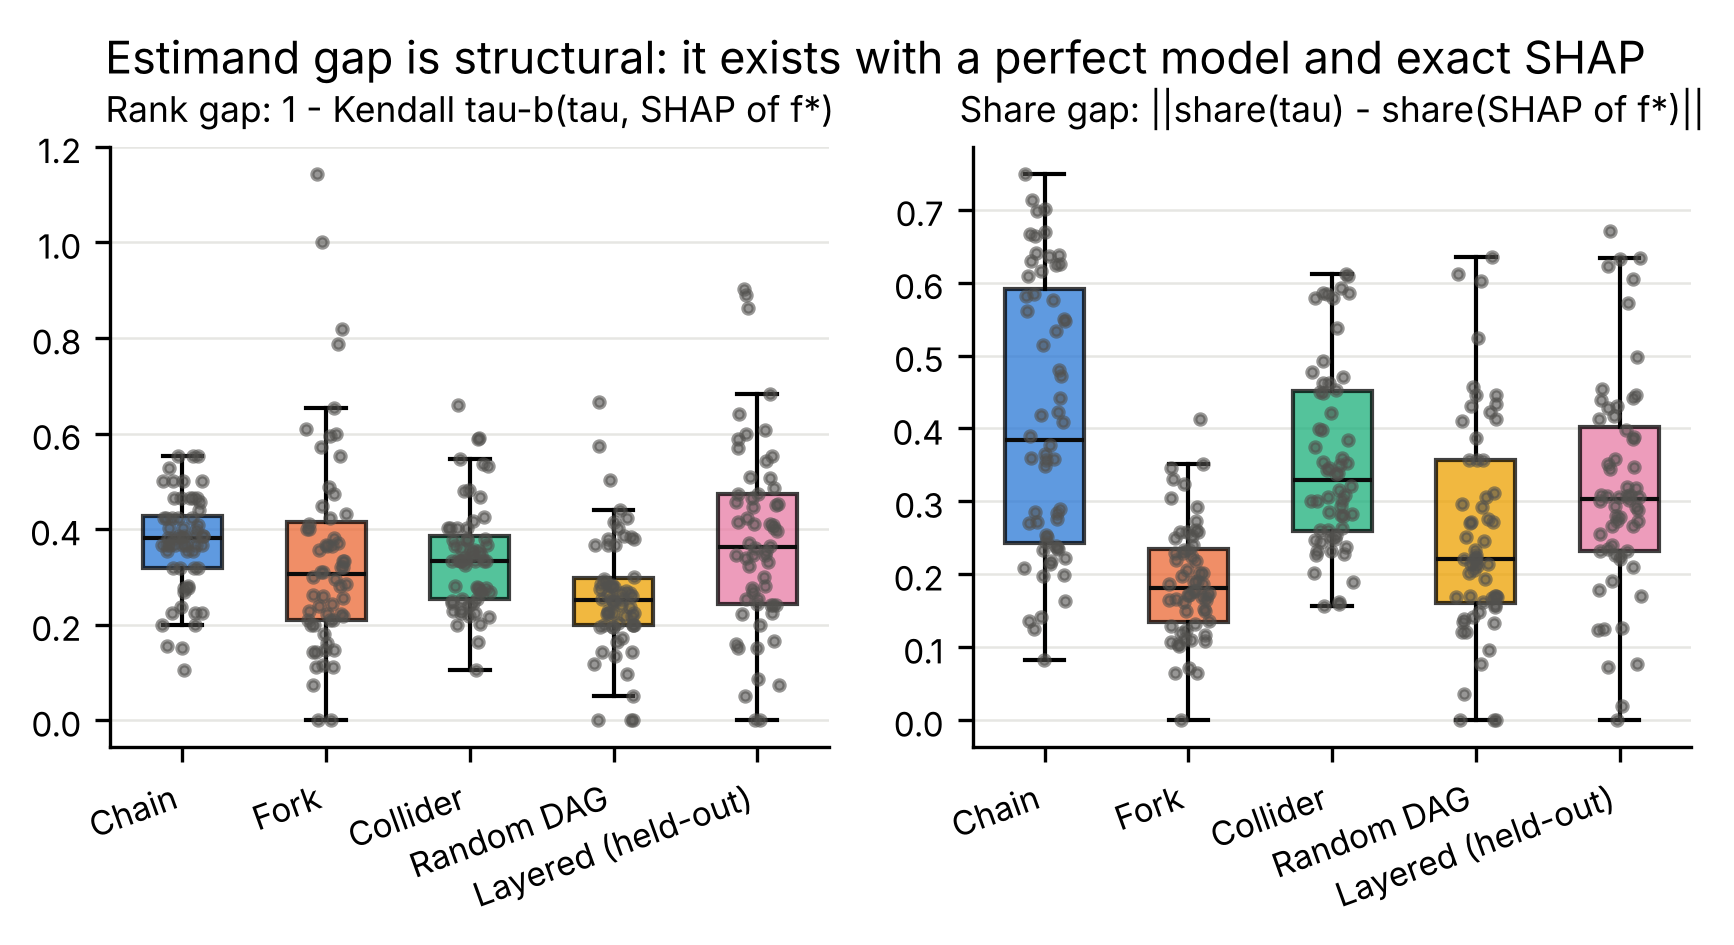

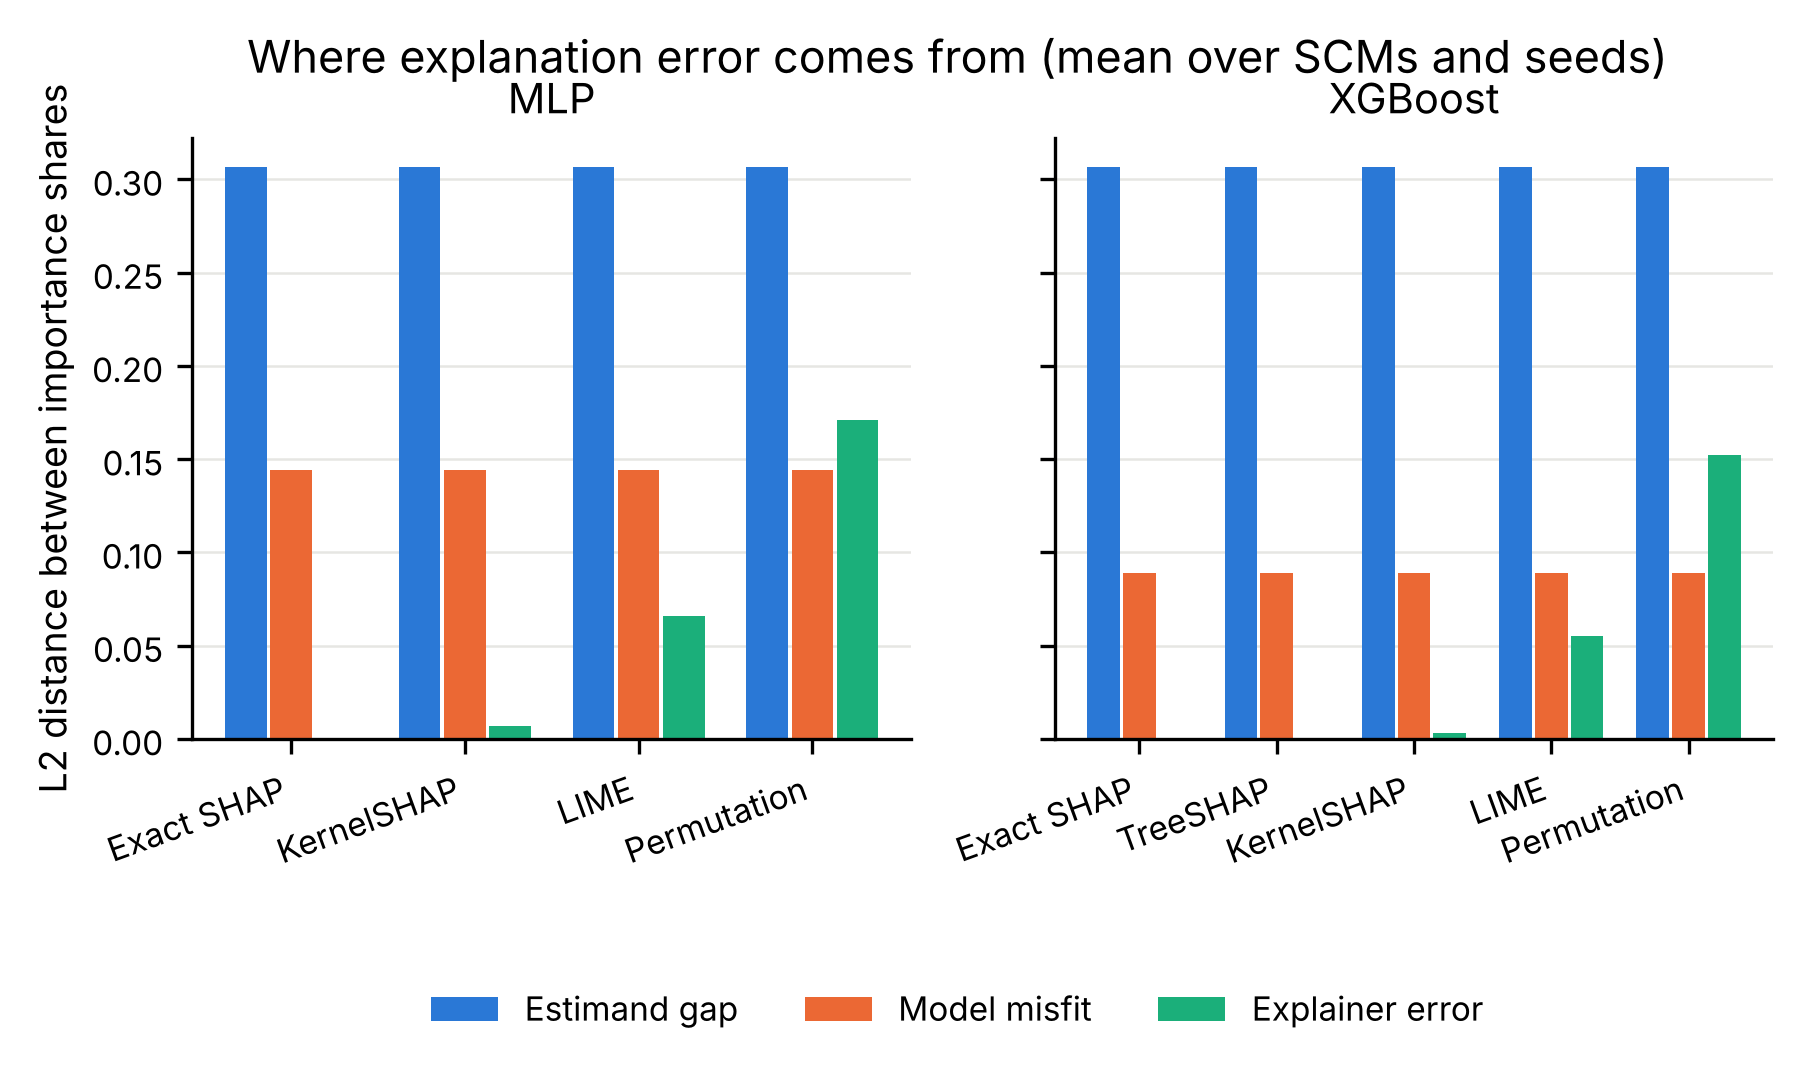

In [8]:
display(pd.read_csv(RES / "tables" / "estimand_gap_by_family.csv").round(3))
display(Image(filename=str(RES / "figures" / "fig_estimand_gap_by_family.png"), width=800))
display(Image(filename=str(RES / "figures" / "fig_error_decomposition_share.png"), width=800))

**Diagnostic performance.** Pooled scores per protocol (Spearman between predicted and actual error; AUROC for flagging rows
above the training median). Two targets: the **share error** (how much importance mass is misallocated) and the **rank error**
(1 − Kendall τ-b on ≤ 10 features).

In [9]:
scores = pd.read_csv(RES / "tables" / "diagnostic_scores.csv")
pooled = scores[(scores.fold == "pooled")].pivot_table(index=["target", "method"], columns="protocol", values=["spearman", "r2", "auroc_high_error"])
pooled.loc[["total_error_rank", "total_error_share_l2"]].round(3)

auroc_high_error                                 r2                           spearman                  
protocol                                        designated_split grouped_cv  logfo designated_split grouped_cv  logfo designated_split grouped_cv  logfo
target               method                                                                                                                             
total_error_rank     baseline_constant                     0.500      0.442  0.398           -0.000     -0.008 -0.035            0.000     -0.110 -0.236
                     baseline_correlation_only             0.395      0.510  0.412           -0.077     -0.005 -0.060           -0.201      0.011 -0.209
                     baseline_disagreement_only            0.566      0.604  0.590            0.019      0.058  0.033            0.144      0.220  0.185
                     baseline_max_vif                      0.426      0.442  0.384           -0.012     -0.010 -0.048           -0.141     -0.114 -0.246
                     baseline_sample_size                  0.614      0.542  0.494            0.017     -0.002 -0.034            0.162      0.070 -0.054
                     baseline_stability_only               0.587      0.598  0.583            0.032      0.044  0.020            0.168      0.189  0.154
                     baseline_test_error                   0.482      0.538  0.477           -0.004      0.000 -0.051            0.022      0.075 -0.062
                     meta_gbm                              0.595      0.668  0.615           -0.011      0.115  0.022            0.197      0.338  0.218
                     meta_rf                               0.603      0.645  0.606           -0.040      0.092  0.022            0.197      0.311  0.204
                     meta_ridge                            0.612      0.662  0.623           -0.021      0.120  0.022            0.198      0.326  0.228
total_error_share_l2 baseline_constant                     0.500      0.474  0.341           -0.011     -0.003 -0.075            0.000     -0.061 -0.351
                     baseline_correlation_only             0.535      0.524  0.389           -0.019     -0.001 -0.271            0.105      0.054 -0.226
                     baseline_disagreement_only            0.670      0.663  0.613            0.135      0.138  0.065            0.384      0.339  0.231
                     baseline_max_vif                      0.422      0.517  0.363           -0.041      0.003 -0.089           -0.127      0.045 -0.287
                     baseline_sample_size                  0.528      0.589  0.534           -0.060      0.050 -0.033            0.070      0.188  0.071
                     baseline_stability_only               0.587      0.597  0.541            0.072      0.083  0.028            0.251      0.226  0.117
                     baseline_test_error                   0.723      0.700  0.671            0.213      0.183  0.128            0.464      0.405  0.358
                     meta_gbm                              0.751      0.824  0.756            0.099      0.529  0.325            0.478      0.652  0.524
                     meta_rf                               0.738      0.832  0.764            0.119      0.561  0.382            0.451      0.665  0.543
                     meta_ridge                            0.671      0.784  0.714            0.170      0.473  0.216            0.481      0.589  0.473

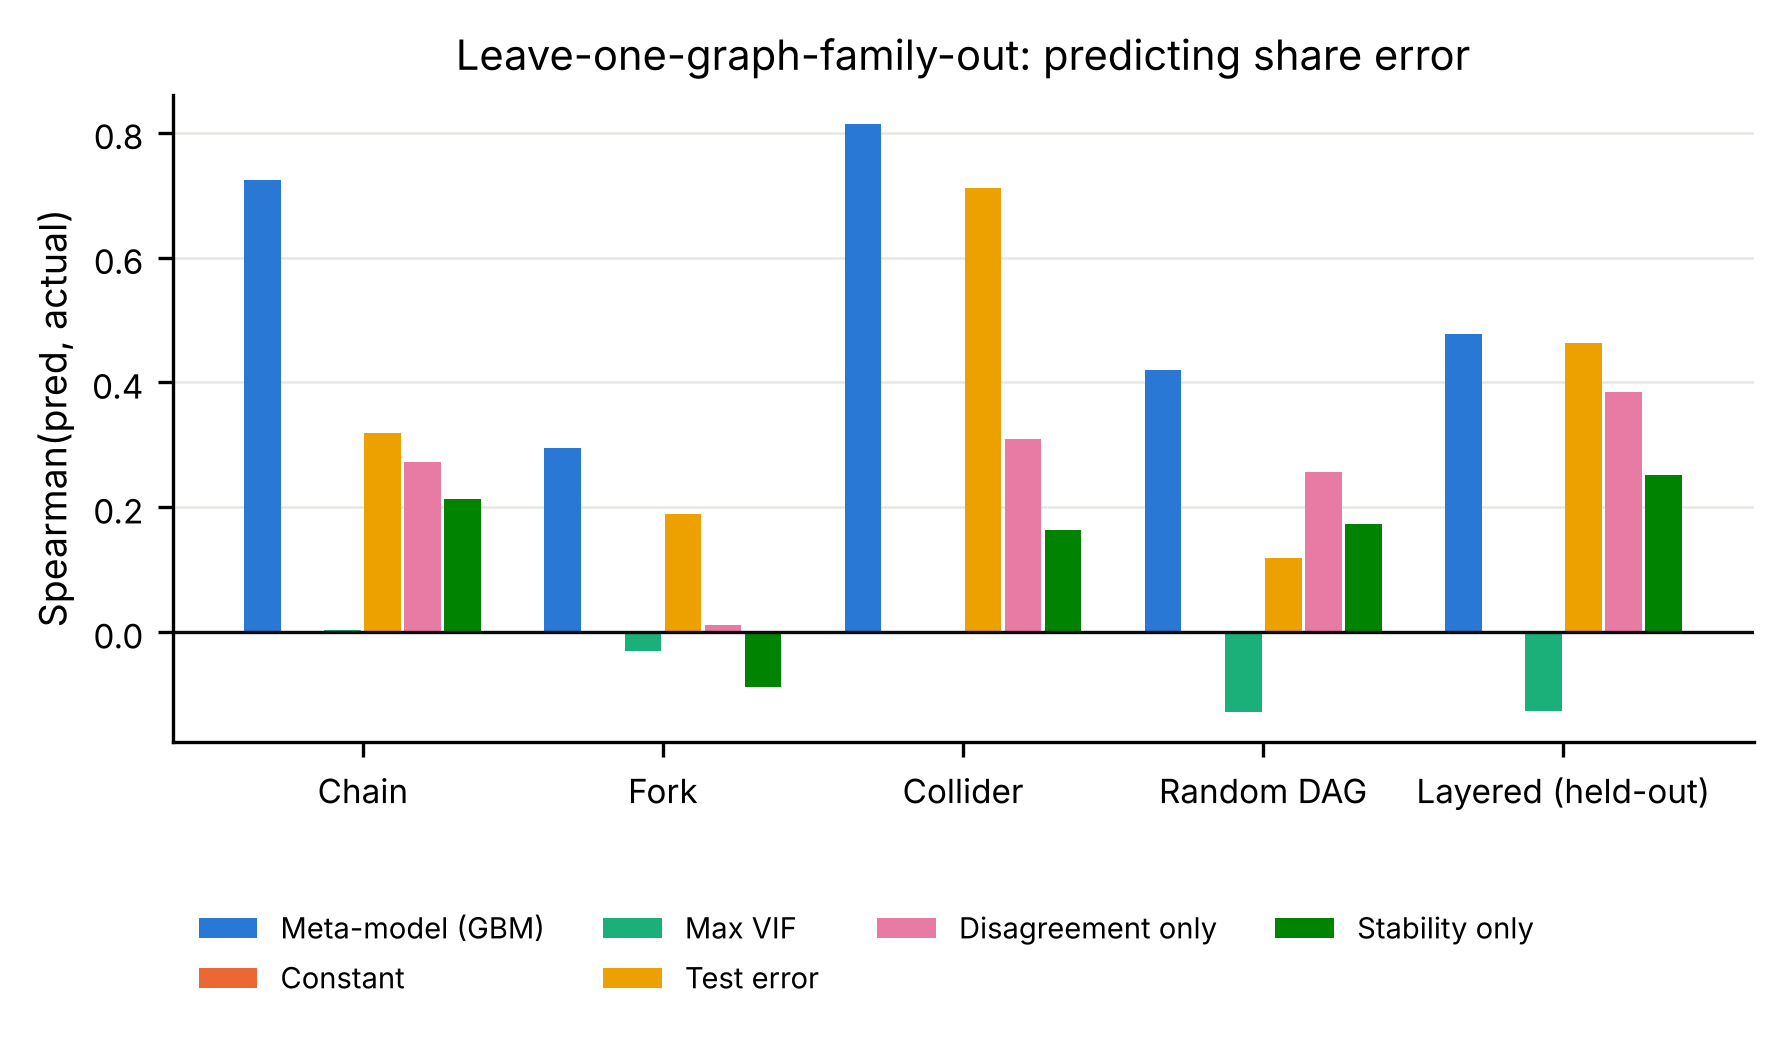

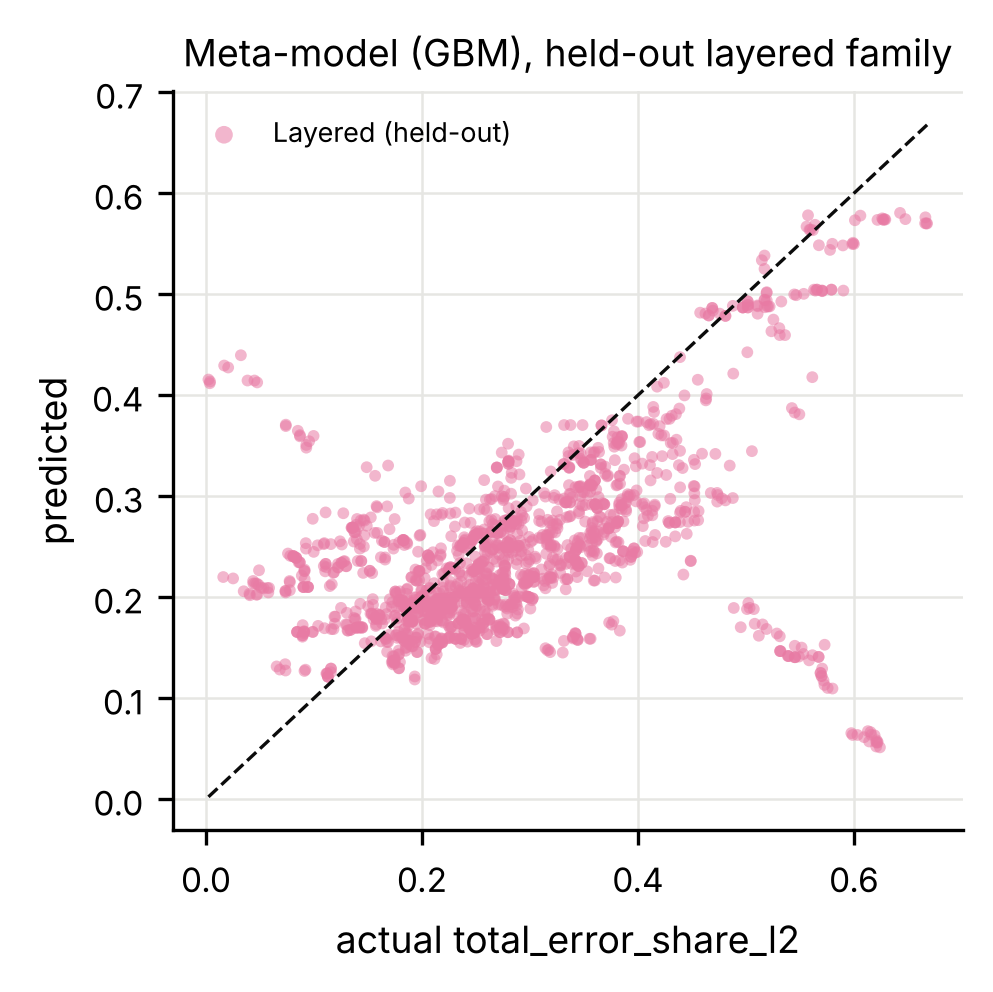

In [10]:
display(Image(filename=str(RES / "figures" / "fig_logfo_spearman_total_error_share_l2.png"), width=850))
display(Image(filename=str(RES / "figures" / "fig_pred_vs_actual_designated_split_meta_gbm_total_error_share_l2.png"), width=420))

**Which part of the error is predictable?** The same experiment with each component of the decomposition as the target.
The explainer's and the model's contributions are visible in the observables; the structural estimand gap is largely not —
and since the gap dominates, the total is only moderately predictable and the rank error hardly at all.

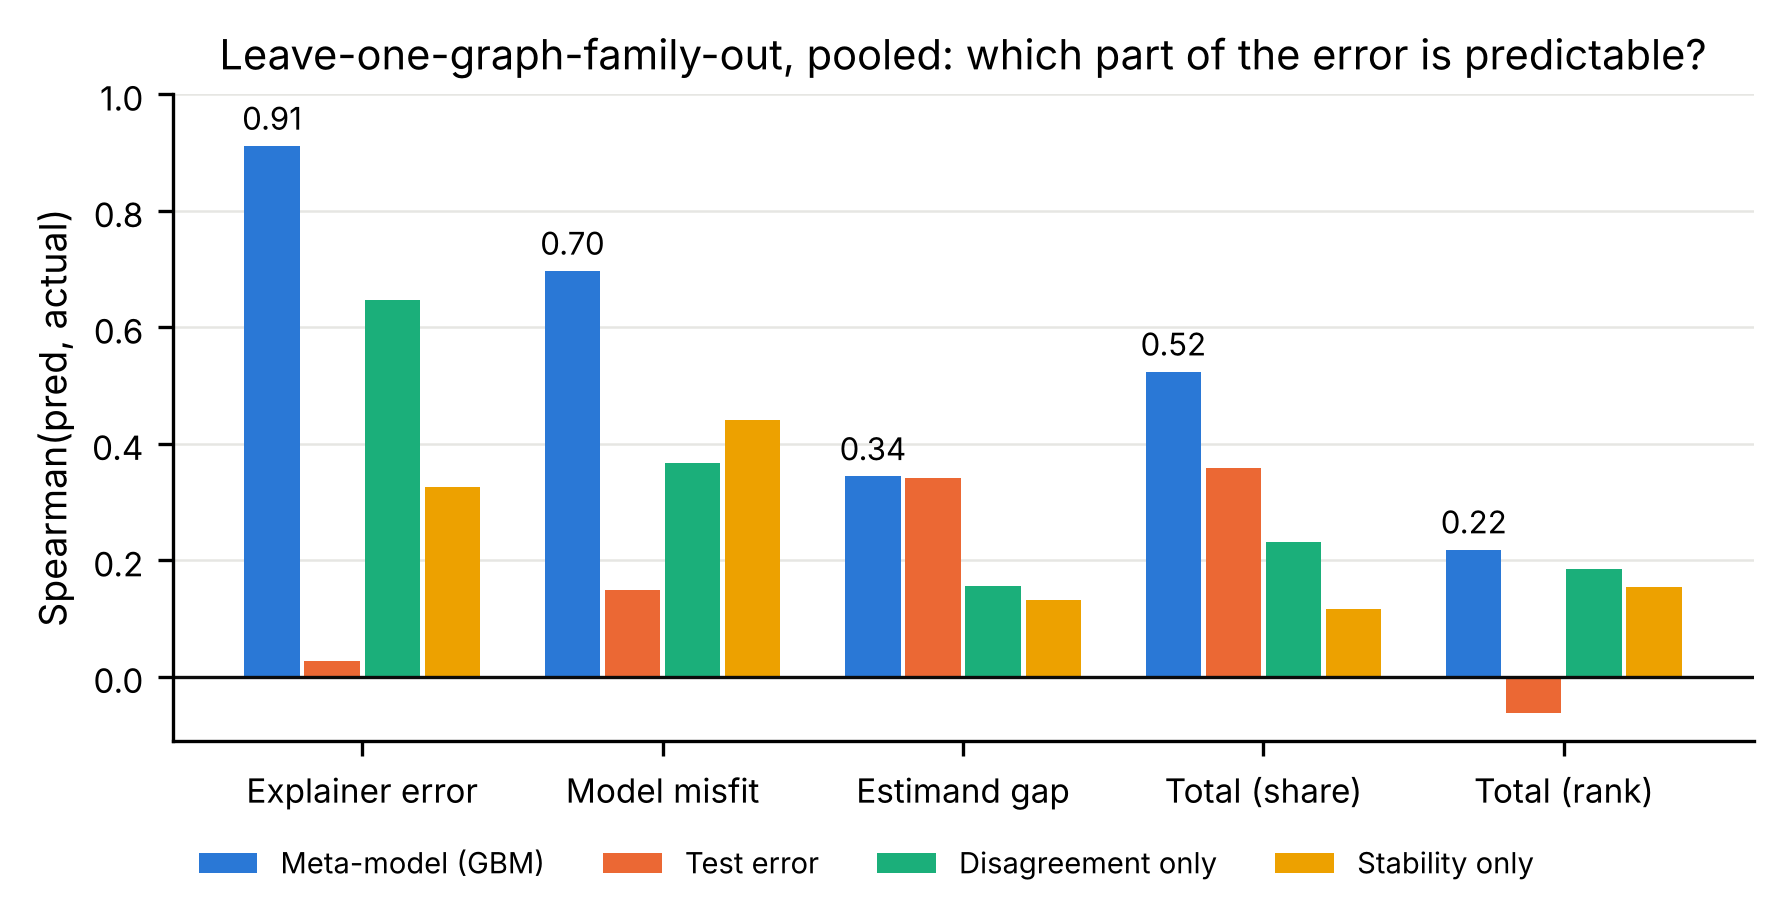

method,meta_gbm,meta_rf,meta_ridge,baseline_test_error,baseline_disagreement_only,baseline_stability_only,baseline_max_vif
target,,,,,,,
explainer_error_share,0.911,0.965,0.834,0.027,0.648,0.326,-0.008
model_misfit_share,0.697,0.687,0.664,0.149,0.367,0.440,-0.161
estimand_gap_share,0.344,0.296,0.391,0.341,0.156,0.131,-0.369
total_error_share_l2,0.524,0.543,0.473,0.358,0.231,0.117,-0.287
total_error_rank,0.218,0.204,0.228,-0.062,0.185,0.154,-0.246


In [11]:
display(Image(filename=str(RES / "figures" / "fig_component_predictability_logfo_spearman.png"), width=850))
comp = scores[(scores.fold == "pooled") & (scores.protocol == "logfo")].pivot_table(index="target", columns="method", values="spearman")
comp.loc[["explainer_error_share", "model_misfit_share", "estimand_gap_share", "total_error_share_l2", "total_error_rank"],
         ["meta_gbm", "meta_rf", "meta_ridge", "baseline_test_error", "baseline_disagreement_only", "baseline_stability_only", "baseline_max_vif"]].round(3)

**Is the gain over the best baseline real?** Paired cluster bootstrap over SCMs (2000 resamples) and Wilcoxon signed-rank on per-SCM absolute errors (share-error target, LOGFO).

In [12]:
tests = pd.read_csv(RES / "tables" / "paired_tests.csv")
cols = ["target", "protocol", "method_b", "mae_gain", "mae_gain_ci_lo", "mae_gain_ci_hi", "spearman_gain", "spearman_gain_ci_lo", "spearman_gain_ci_hi", "wilcoxon_p", "frac_scms_a_better"]
tests[(tests.target == "total_error_share_l2") & (tests.protocol == "logfo")][cols].round(3)

,target,protocol,method_b,mae_gain,mae_gain_ci_lo,mae_gain_ci_hi,spearman_gain,spearman_gain_ci_lo,spearman_gain_ci_hi,wilcoxon_p,frac_scms_a_better
27,total_error_share_l2,logfo,meta_rf,-0.002,-0.005,0.000,-0.020,-0.043,0.004,0.089,0.463
28,total_error_share_l2,logfo,meta_ridge,0.009,0.004,0.015,0.050,-0.024,0.119,0.000,0.590
29,total_error_share_l2,logfo,baseline_constant,0.033,0.024,0.042,0.874,0.740,1.003,0.000,0.687
30,total_error_share_l2,logfo,baseline_correlation_only,0.043,0.035,0.052,0.748,0.630,0.865,0.000,0.727
31,total_error_share_l2,logfo,baseline_max_vif,0.034,0.025,0.043,0.810,0.681,0.939,0.000,0.703
32,total_error_share_l2,logfo,baseline_test_error,0.019,0.012,0.026,0.168,0.075,0.253,0.000,0.647
33,total_error_share_l2,logfo,baseline_sample_size,0.030,0.022,0.038,0.452,0.336,0.566,0.000,0.703
34,total_error_share_l2,logfo,baseline_disagreement_only,0.023,0.016,0.031,0.292,0.197,0.385,0.000,0.693
35,total_error_share_l2,logfo,baseline_stability_only,0.027,0.020,0.035,0.407,0.311,0.497,0.000,0.730


**Which observables carry the signal?** Permutation importance of the meta-model trained on the four training families and scored on the held-out layered family.

,feature,importance_mean,importance_std
0,mean_abs_corr_xy,0.188,2.200e-02
1,attribution_gini,0.131,1.080e-02
2,mi_xy_mean,0.053,4.700e-03
3,mi_xy_max,0.017,3.800e-03
4,disagreement_l2_mean,0.014,2.200e-03
5,disagreement_l2_vs_lime,0.007,1.400e-03
6,train_r2,0.006,7.000e-04
7,mutual_info_max,0.004,1.600e-03
8,sensitivity,0.004,5.000e-04
9,local_dispersion,0.003,5.000e-04


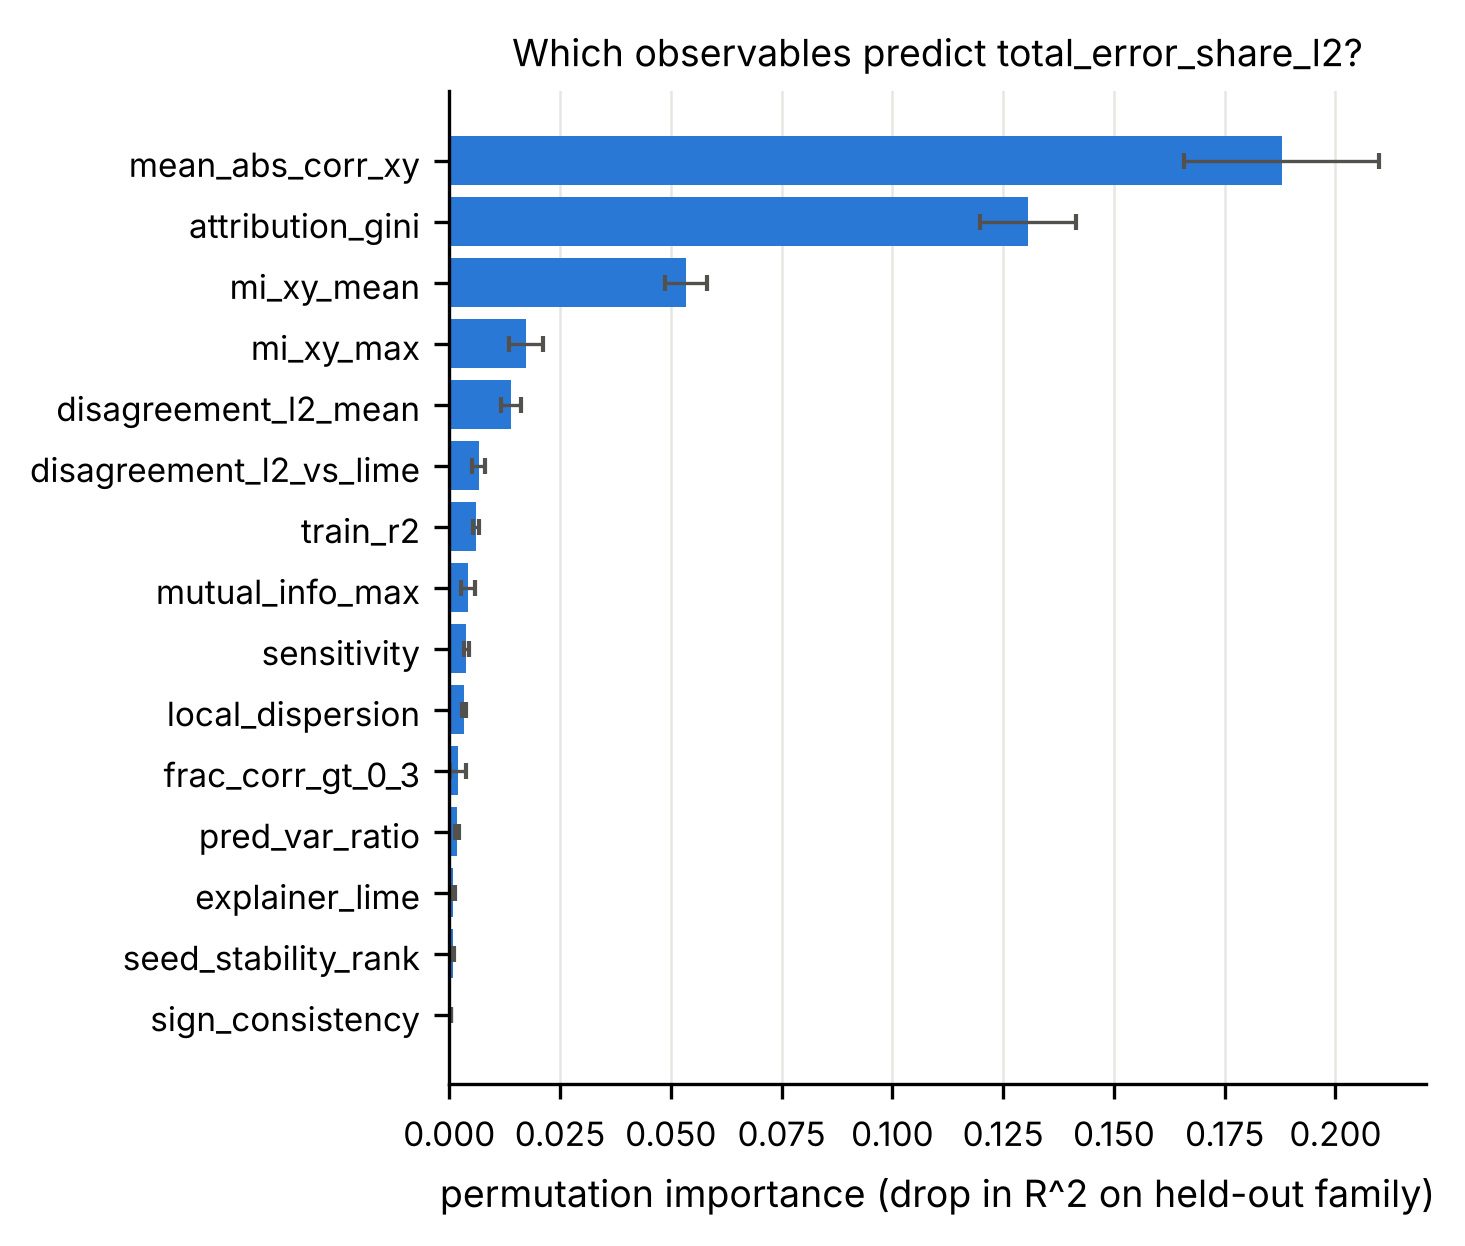

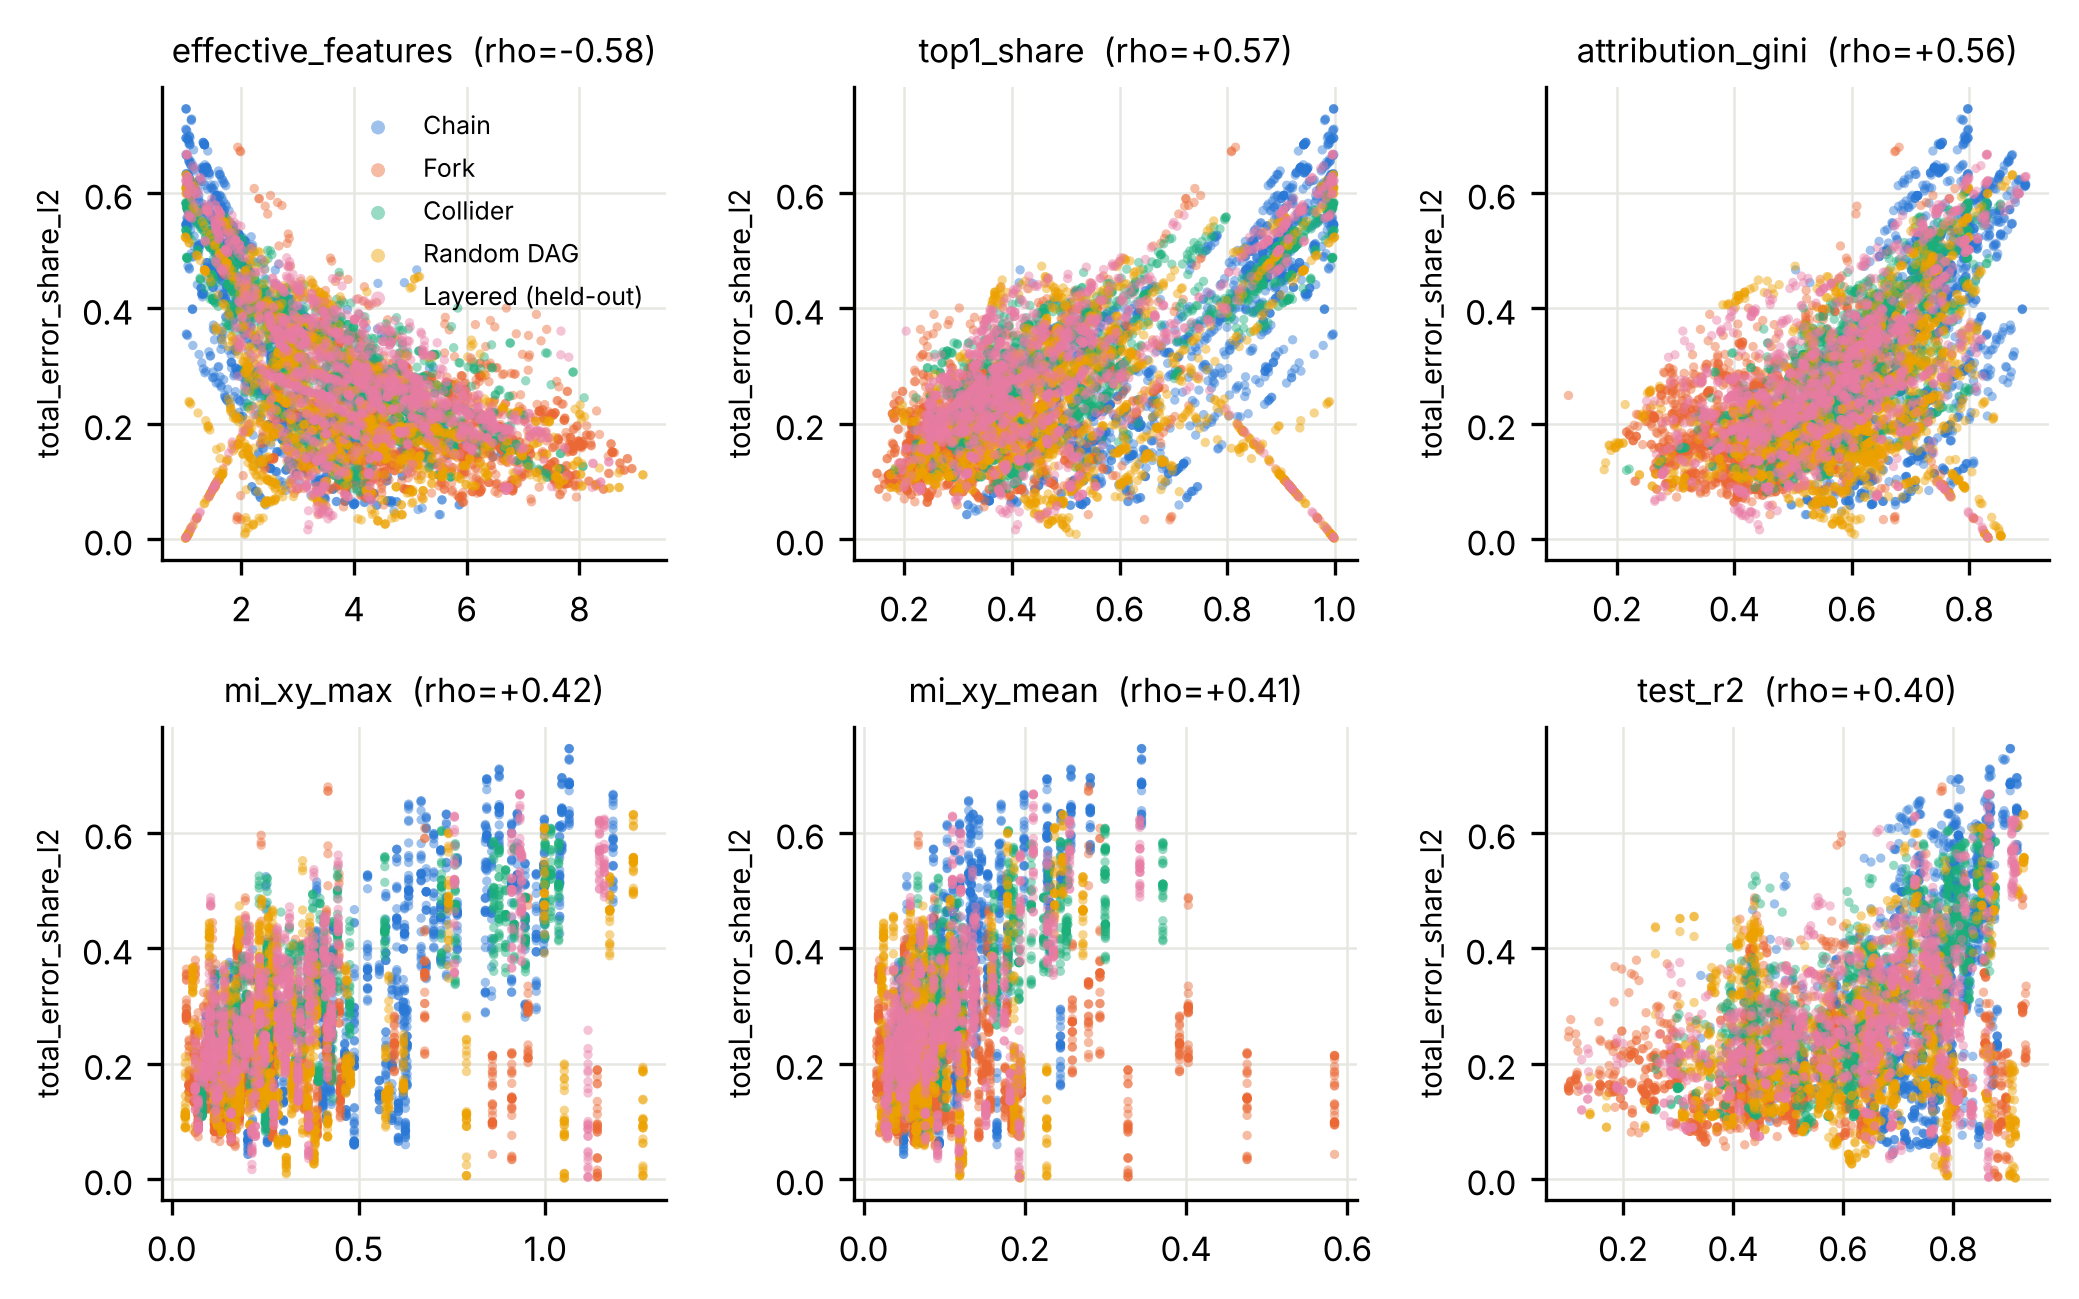

In [13]:
display(pd.read_csv(RES / "tables" / "feature_importance_total_error_share_l2.csv").head(12).round(4))
display(Image(filename=str(RES / "figures" / "fig_feature_importance_total_error_share_l2.png"), width=520))
display(Image(filename=str(RES / "figures" / "fig_observables_vs_total_error_share_l2.png"), width=850))

**Stricter question:** for a *fixed* explainer and model, can the diagnostic still rank SCMs by error? (`by_method` rows of the scores table, LOGFO.)

In [14]:
bm = scores[(scores.protocol == "logfo") & (scores.target == "total_error_share_l2") & scores.fold.str.startswith("by_method")]
bm = bm.assign(subset=bm.fold.str.replace("by_method:", "")).pivot_table(index="subset", columns="method", values="spearman")
bm[[c for c in ["meta_gbm", "meta_rf", "meta_ridge", "baseline_test_error", "baseline_disagreement_only", "baseline_stability_only", "baseline_max_vif"] if c in bm.columns]].round(3)

method,meta_gbm,meta_rf,meta_ridge,baseline_test_error,baseline_disagreement_only,baseline_stability_only,baseline_max_vif
subset,,,,,,,
mlp/exact,0.447,0.457,0.415,0.375,0.159,0.209,-0.232
mlp/kernelshap,0.448,0.462,0.415,0.383,0.196,0.181,-0.229
mlp/lime,0.448,0.465,0.350,0.267,0.244,0.196,-0.268
mlp/permutation,0.530,0.558,0.511,0.438,0.220,0.209,-0.298
xgboost/exact,0.471,0.486,0.400,0.390,0.124,0.126,-0.325
xgboost/kernelshap,0.470,0.484,0.396,0.390,0.136,0.195,-0.325
xgboost/lime,0.468,0.488,0.371,0.305,0.231,0.054,-0.308
xgboost/permutation,0.547,0.566,0.491,0.469,0.187,0.237,-0.327
xgboost/treeshap,0.470,0.486,0.402,0.390,0.124,0.136,-0.325


**Re-running the diagnostic live.** The whole stage-5 evaluation is one function call; here is LOGFO for the GBM
meta-model and two baselines, recomputed in the notebook from the saved tables.

In [15]:
from src.diagnostic import load_meta_table, run_methods, meta_model_factory, baseline_factory
meta = load_meta_table(RES / "errors.csv", RES / "observables.csv", SCMS / "manifest.csv")
methods = {"meta_gbm": meta_model_factory("gbm"), "baseline_test_error": baseline_factory("test_error"), "baseline_constant": baseline_factory("constant")}
sc, preds = run_methods(meta, "total_error_share_l2", methods, "logfo")
sc[~sc.fold.str.startswith("by_method")].pivot_table(index="fold", columns="method", values="spearman").round(3)

method,baseline_constant,baseline_test_error,meta_gbm
fold,,,
chain_mediation,0.000,0.318,0.725
confounded_fork,0.000,0.188,0.295
erdos_renyi_dag,0.000,0.119,0.420
feature_collider,0.000,0.712,0.814
layered,0.000,0.464,0.478
pooled,-0.351,0.358,0.524


## Takeaways

1. **Most explanation error is structural.** With a perfect model and exact SHAP, the attribution still ranks features
   differently from the causal effect (estimand gap), and the gap depends on the graph family. The explainer's own
   approximation error (KernelSHAP, LIME) is small by comparison; permutation importance is the noisiest.
2. **How much importance mass an explanation misallocates is predictable from observable signals** (Spearman ≈ 0.65 on
   unseen SCMs, ≈ 0.52 under leave-one-graph-family-out, AUROC ≈ 0.76), and the diagnostic transfers to graph families it
   never saw, beating every single-signal baseline (see `paired_tests.csv`).
3. **But the predictable part is the model's and the explainer's error** (ρ ≈ 0.70 and 0.91); the structural estimand gap is
   mostly invisible (ρ ≈ 0.34) and the feature *ranking* error hardly predictable (ρ ≈ 0.22). A diagnostic can warn about a
   bad model or explainer, not about SHAP asking a different question than "what if I intervene".
4. **The strongest signals** are attribution concentration (Gini, top-1 share, effective #features), feature–outcome
   association, model fit, and disagreement between explainers and between models; max VIF alone is nearly useless.
5. **Limitations.** Synthetic SCMs with $d \le 10$, additive noise and one outcome; the diagnostic is calibrated
   to this benchmark's families and should be re-validated before use on real data (IHDP / Adult / California Housing
   checks are left as future work).